科学技術・高等教育領域でのLLMの能力測定における離散反応データ行列/連続反応確率データ行列の統合IRT分析


In [1]:
from __future__ import annotations

import time
from dataclasses import dataclass
from typing import Dict, Optional, Tuple, List

import numpy as np
import pandas as pd
from scipy.optimize import minimize, minimize_scalar

In [2]:
D = 1.702

In [3]:
#基礎的な関数、処理
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -40.0, 40.0)))


def logit(p, eps=1e-8):
    p = np.clip(p, eps, 1.0 - eps)
    return np.log(p / (1.0 - p))


def standardize_params(a, b, theta_p, theta_bin):
    parts = []
    if len(theta_p):
        parts.append(theta_p)
    if len(theta_bin):
        parts.append(theta_bin)
    base = np.concatenate(parts) if parts else np.array([0.0, 1.0])
    m = float(base.mean())
    s = float(base.std())
    if not np.isfinite(s) or s < 1e-8:
        s = 1.0
    return a * s, (b - m) / s, (theta_p - m) / s, (theta_bin - m) / s


def rmse(x, y):
    if len(x) == 0:
        return np.nan
    return float(np.sqrt(np.mean((np.asarray(x) - np.asarray(y)) ** 2)))


def corr(x, y):
    if len(x) < 2:
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])

def to_numpy_or_empty(x, n_items=None):
    """
    Convert DataFrame/array/None to numpy array.
    If x is None, return an empty array with shape (0, n_items).
    """
    if x is None:
        if n_items is None:
            return np.empty((0, 0))
        return np.empty((0, n_items))
    if isinstance(x, pd.DataFrame):
        return x.to_numpy(dtype=float)
    return np.asarray(x, dtype=float)


def infer_n_items(*arrays):
    for x in arrays:
        if x is None:
            continue
        if isinstance(x, pd.DataFrame):
            return x.shape[1]
        arr = np.asarray(x)
        if arr.ndim == 2:
            return arr.shape[1]
    raise ValueError("At least one non-empty 2D data matrix is required.")


def make_variance_from_s2(s2, R_l, c_tau=0.25):
    """
    Construct probability-channel analysis variance.

    v = s^2 / R_l + tau^2
    tau^2 = c_tau / R_l

    s2 is the empirical variance of repeated probability measurements.
    """
    if s2.size == 0:
        return s2
    tau2 = c_tau / R_l
    return s2 / R_l + tau2

def standardize_params_mixed(a, b, theta_full_p, theta_bin, theta_mix):
    parts = []
    if len(theta_full_p):
        parts.append(theta_full_p)
    if len(theta_bin):
        parts.append(theta_bin)
    if len(theta_mix):
        parts.append(theta_mix)

    if not parts:
        return a, b, theta_full_p, theta_bin, theta_mix

    theta_all = np.concatenate(parts)
    mean = theta_all.mean()
    sd = theta_all.std()

    if not np.isfinite(sd) or sd < 1e-8:
        sd = 1.0

    a_new = a * sd
    b_new = (b - mean) / sd

    theta_full_p_new = (theta_full_p - mean) / sd
    theta_bin_new = (theta_bin - mean) / sd
    theta_mix_new = (theta_mix - mean) / sd

    return a_new, b_new, theta_full_p_new, theta_bin_new, theta_mix_new

In [4]:
#初期値の見積もり。NaNは初期値計算に含まない形になっている。ただし、全てNaNの項目があるなら、最初から除外すること。
def initialize_params_mixed(
    p_full,
    v_full,
    r_bin,
    p_mix,
    v_mix,
    r_mix,
    mask_mix,
    R_b,
    init_ab=None,
):
    """
    Initialize item parameters and abilities for:
      1. full probability respondents
      2. full binary respondents
      3. item-wise mixed respondents
    """
    n_items = infer_n_items(p_full, r_bin, p_mix, r_mix, mask_mix)

    n_full_p = p_full.shape[0]
    n_bin = r_bin.shape[0]
    n_mix = p_mix.shape[0]

    if init_ab is None:
        item_means = []

        if n_full_p:
            item_means.append(np.nanmean(p_full, axis=0))

        if n_bin:
            item_means.append(np.nanmean(r_bin / R_b, axis=0))

        if n_mix:
            # mixed observed probability equivalent for initialization
            mix_prob_equiv = np.where(mask_mix == 1, p_mix, r_mix / R_b)
            item_means.append(np.nanmean(mix_prob_equiv, axis=0))

        p_item = np.nanmean(np.vstack(item_means), axis=0)
        p_item = np.clip(p_item, 1e-4, 1.0 - 1e-4)

        a = np.ones(n_items)
        b = -logit(p_item) / D
    else:
        a, b = [np.asarray(z, dtype=float).copy() for z in init_ab]

    # theta initialization
    if n_full_p:
        row_mean = np.nanmean(p_full, axis=1)
        theta_full_p = logit(np.clip(row_mean, 1e-4, 1.0 - 1e-4)) / D
    else:
        theta_full_p = np.array([])

    if n_bin:
        row_mean = np.nanmean(r_bin / R_b, axis=1)
        theta_bin = logit(np.clip(row_mean, 1e-4, 1.0 - 1e-4)) / D
    else:
        theta_bin = np.array([])

    if n_mix:
        mix_prob_equiv = np.full_like(p_mix, np.nan, dtype=float)
        # logprobsが使えるところはp_mixを入れる
        prob_available = (
            (mask_mix == 1)
            & np.isfinite(p_mix)
        )
        mix_prob_equiv[prob_available] = p_mix[prob_available]

        # それ以外でbinaryがあるところは r/R_b を入れる
        bin_available = (
            ~np.isfinite(mix_prob_equiv)
            & np.isfinite(r_mix)
        )
        mix_prob_equiv[bin_available] = r_mix[bin_available] / R_b
        
        row_mean = np.nanmean(mix_prob_equiv, axis=1)
        theta_mix = logit(np.clip(row_mean, 1e-4, 1.0 - 1e-4)) / D
    else:
        theta_mix = np.array([])

    return standardize_params_mixed(a, b, theta_full_p, theta_bin, theta_mix)

In [5]:
#thetaの更新用。
def probability_theta_objective(theta, p_g, v_g, a, b):
    mu = sigmoid(D * a * (theta - b))
    valid = np.isfinite(p_g) & np.isfinite(v_g)
    if not np.any(valid):
        return 0.0
    return float(0.5 * np.sum((p_g[valid] - mu[valid]) ** 2 / v_g[valid]))


def update_theta_full_probability(p_full, v_full, a, b, bounds=(-6.0, 6.0)):
    if p_full.shape[0] == 0:
        return np.array([])

    theta_hat = np.zeros(p_full.shape[0])

    for g in range(p_full.shape[0]):
        res = minimize_scalar(
            lambda th: probability_theta_objective(th, p_full[g], v_full[g], a, b),
            bounds=bounds,
            method="bounded",
            options={"xatol": 1e-5},
        )
        theta_hat[g] = res.x

    return theta_hat

def binary_theta_objective(theta, r_g, R_b, a, b):
    mu = sigmoid(D * a * (theta - b))
    mu = np.clip(mu, 1e-12, 1.0 - 1e-12)
    valid = np.isfinite(r_g)
    if not np.any(valid):
        return 0.0

    return float(
        -np.sum(
            r_g[valid] * np.log(mu[valid])
            + (R_b - r_g[valid]) * np.log(1.0 - mu[valid])
        )
    )


def update_theta_binary(r_bin, R_b, a, b, bounds=(-6.0, 6.0)):
    if r_bin.shape[0] == 0:
        return np.array([])

    theta_hat = np.zeros(r_bin.shape[0])

    for g in range(r_bin.shape[0]):
        res = minimize_scalar(
            lambda th: binary_theta_objective(th, r_bin[g], R_b, a, b),
            bounds=bounds,
            method="bounded",
            options={"xatol": 1e-5},
        )
        theta_hat[g] = res.x

    return theta_hat

def mixed_theta_objective(theta, p_g, v_g, r_g, mask_g, R_b, a, b):
    """
    mask_g[i] == 1:
        logprobs/probability observation is available.
        Use probability term if p_g and v_g are finite.
        Also use binary term if r_g is finite.

    mask_g[i] == 0:
        logprobs/probability observation is unavailable.
        Use binary term if r_g is finite.
    """
    mu = sigmoid(D * a * (theta - b))
    mu_clip = np.clip(mu, 1e-12, 1.0 - 1e-12)

    value = 0.0

    # probability term: only when mask == 1 and p/v are available
    prob_idx = (
        (mask_g == 1)
        & np.isfinite(p_g)
        & np.isfinite(v_g)
    )

    # binary term: use whenever r is available
    # this means:
    #   mask == 0 -> binary only
    #   mask == 1 with finite r -> probability + binary
    bin_idx = np.isfinite(r_g)

    if np.any(prob_idx):
        value += 0.5 * np.sum(
            (p_g[prob_idx] - mu[prob_idx]) ** 2 / v_g[prob_idx]
        )

    if np.any(bin_idx):
        value += -np.sum(
            r_g[bin_idx] * np.log(mu_clip[bin_idx])
            + (R_b - r_g[bin_idx]) * np.log(1.0 - mu_clip[bin_idx])
        )

    return float(value)


def update_theta_mixed(p_mix, v_mix, r_mix, mask_mix, R_b, a, b, bounds=(-6.0, 6.0)):
    if p_mix.shape[0] == 0:
        return np.array([])

    theta_hat = np.zeros(p_mix.shape[0])

    for g in range(p_mix.shape[0]):
        res = minimize_scalar(
            lambda th: mixed_theta_objective(
                th,
                p_mix[g],
                v_mix[g],
                r_mix[g],
                mask_mix[g],
                R_b,
                a,
                b,
            ),
            bounds=bounds,
            method="bounded",
            options={"xatol": 1e-5},
        )
        theta_hat[g] = res.x

    return theta_hat

In [6]:
#項目の更新用
def item_objective_and_grad_mixed(
    z,
    p_full_j,
    v_full_j,
    r_bin_j,
    p_mix_j,
    v_mix_j,
    r_mix_j,
    mask_mix_j,
    R_b,
    theta_full_p,
    theta_bin,
    theta_mix,
    ridge=1e-4,
):
    alpha, bj = z
    aj = np.exp(alpha)

    value = 0.0
    grad_alpha = 0.0
    grad_b = 0.0

    # 1. full probability group
    if len(theta_full_p):
        valid = np.isfinite(p_full_j) & np.isfinite(v_full_j)
        if np.any(valid):
            th = theta_full_p[valid]
            eta = D * aj * (th - bj)
            mu = sigmoid(eta)
            residual = mu - p_full_j[valid]
            w = 1.0 / v_full_j[valid]

            value += 0.5 * np.sum(w * residual ** 2)

            dL_deta = w * residual * mu * (1.0 - mu)
            d_eta_da = D * (th - bj)
            d_eta_db = -D * aj

            grad_alpha += np.sum(dL_deta * d_eta_da) * aj
            grad_b += np.sum(dL_deta * d_eta_db)

    # 2. full binary group
    if len(theta_bin):
        valid = np.isfinite(r_bin_j)
        if np.any(valid):
            th = theta_bin[valid]
            eta = D * aj * (th - bj)
            mu = np.clip(sigmoid(eta), 1e-12, 1.0 - 1e-12)

            rj = r_bin_j[valid]

            value += -np.sum(
                rj * np.log(mu)
                + (R_b - rj) * np.log(1.0 - mu)
            )

            dL_deta = R_b * mu - rj
            d_eta_da = D * (th - bj)
            d_eta_db = -D * aj

            grad_alpha += np.sum(dL_deta * d_eta_da) * aj
            grad_b += np.sum(dL_deta * d_eta_db)

    # 3. mixed group: probability part
    if len(theta_mix):
        prob_idx = (mask_mix_j == 1) & np.isfinite(p_mix_j) & np.isfinite(v_mix_j)

        if np.any(prob_idx):
            th = theta_mix[prob_idx]
            eta = D * aj * (th - bj)
            mu = sigmoid(eta)
            residual = mu - p_mix_j[prob_idx]
            w = 1.0 / v_mix_j[prob_idx]

            value += 0.5 * np.sum(w * residual ** 2)

            dL_deta = w * residual * mu * (1.0 - mu)
            d_eta_da = D * (th - bj)
            d_eta_db = -D * aj

            grad_alpha += np.sum(dL_deta * d_eta_da) * aj
            grad_b += np.sum(dL_deta * d_eta_db)

        # 4. mixed group: binary part
        bin_idx = np.isfinite(r_mix_j)

        if np.any(bin_idx):
            th = theta_mix[bin_idx]
            eta = D * aj * (th - bj)
            mu = np.clip(sigmoid(eta), 1e-12, 1.0 - 1e-12)

            rj = r_mix_j[bin_idx]

            value += -np.sum(
                rj * np.log(mu)
                + (R_b - rj) * np.log(1.0 - mu)
            )

            dL_deta = R_b * mu - rj
            d_eta_da = D * (th - bj)
            d_eta_db = -D * aj

            grad_alpha += np.sum(dL_deta * d_eta_da) * aj
            grad_b += np.sum(dL_deta * d_eta_db)

    # ridge
    if ridge is not None and ridge > 0:
        value += ridge * (alpha ** 2 + bj ** 2)
        grad_alpha += 2.0 * ridge * alpha
        grad_b += 2.0 * ridge * bj

    return float(value), np.array([grad_alpha, grad_b])

def update_items_mixed(
    p_full,
    v_full,
    r_bin,
    p_mix,
    v_mix,
    r_mix,
    mask_mix,
    R_b,
    a,
    b,
    theta_full_p,
    theta_bin,
    theta_mix,
    item_maxiter=50,
    ridge=1e-4,
):
    n_items = len(a)
    new_a = a.copy()
    new_b = b.copy()

    for j in range(n_items):
        p_full_j = p_full[:, j] if p_full.shape[0] else np.array([])
        v_full_j = v_full[:, j] if v_full.shape[0] else np.array([])
        r_bin_j = r_bin[:, j] if r_bin.shape[0] else np.array([])

        p_mix_j = p_mix[:, j] if p_mix.shape[0] else np.array([])
        v_mix_j = v_mix[:, j] if v_mix.shape[0] else np.array([])
        r_mix_j = r_mix[:, j] if r_mix.shape[0] else np.array([])
        mask_mix_j = mask_mix[:, j] if mask_mix.shape[0] else np.array([])

        z0 = np.array([np.log(max(a[j], 1e-4)), b[j]])

        res = minimize(
            lambda z: item_objective_and_grad_mixed(
                z,
                p_full_j,
                v_full_j,
                r_bin_j,
                p_mix_j,
                v_mix_j,
                r_mix_j,
                mask_mix_j,
                R_b,
                theta_full_p,
                theta_bin,
                theta_mix,
                ridge=ridge,
            )[0],
            z0,
            jac=lambda z: item_objective_and_grad_mixed(
                z,
                p_full_j,
                v_full_j,
                r_bin_j,
                p_mix_j,
                v_mix_j,
                r_mix_j,
                mask_mix_j,
                R_b,
                theta_full_p,
                theta_bin,
                theta_mix,
                ridge=ridge,
            )[1],
            method="L-BFGS-B",
            bounds=[(np.log(0.05), np.log(5.0)), (-5.0, 5.0)],
            options={"maxiter": item_maxiter, "ftol": 1e-7, "gtol": 1e-6, "maxls": 30},
        )

        new_a[j] = np.exp(res.x[0])
        new_b[j] = res.x[1]

    return new_a, new_b

#以下、収束判定参考用
def objective_components_mixed(
    p_full,
    v_full,
    r_bin,
    p_mix,
    v_mix,
    r_mix,
    mask_mix,
    R_b,
    a,
    b,
    theta_full_p,
    theta_bin,
    theta_mix,
    ridge=1e-4,
):
    out = {
        "prob_full": 0.0,
        "bin_full": 0.0,
        "mix_prob": 0.0,
        "mix_bin": 0.0,
        "ridge": 0.0,
    }

    # full probability
    if len(theta_full_p):
        eta = D * a[None, :] * (theta_full_p[:, None] - b[None, :])
        mu = sigmoid(eta)
        valid = np.isfinite(p_full) & np.isfinite(v_full)
        out["prob_full"] = float(
            0.5 * np.sum(((p_full - mu) ** 2 / v_full)[valid])
        )

    # full binary
    if len(theta_bin):
        eta = D * a[None, :] * (theta_bin[:, None] - b[None, :])
        mu = np.clip(sigmoid(eta), 1e-12, 1.0 - 1e-12)
        valid = np.isfinite(r_bin)
        out["bin_full"] = float(
            -np.sum(
                (r_bin * np.log(mu) + (R_b - r_bin) * np.log(1.0 - mu))[valid]
            )
        )

    # mixed
    if len(theta_mix):
        eta = D * a[None, :] * (theta_mix[:, None] - b[None, :])
        mu = sigmoid(eta)
        mu_clip = np.clip(mu, 1e-12, 1.0 - 1e-12)

        prob_idx = (mask_mix == 1) & np.isfinite(p_mix) & np.isfinite(v_mix)
        bin_idx = np.isfinite(r_mix)

        if np.any(prob_idx):
            out["mix_prob"] = float(
                0.5 * np.sum(((p_mix - mu) ** 2 / v_mix)[prob_idx])
            )

        if np.any(bin_idx):
            out["mix_bin"] = float(
                -np.sum(
                    (
                        r_mix * np.log(mu_clip)
                        + (R_b - r_mix) * np.log(1.0 - mu_clip)
                    )[bin_idx]
                )
            )

    if ridge is not None and ridge > 0:
        alpha = np.log(np.clip(a, 1e-12, None))
        out["ridge"] = float(ridge * np.sum(alpha ** 2 + b ** 2))

    out["total"] = (
        out["prob_full"]
        + out["bin_full"]
        + out["mix_prob"]
        + out["mix_bin"]
        + out["ridge"]
    )

    return out

In [7]:
# 標準誤差計算。ただし、a,bの推定ではtheta固定、そしてtheta推定ではa,bを固定しているので、同時推定誤差を無視しており、厳密なHessian計算ではないことに留意。
def compute_se_mixed(
    p_full,
    v_full,
    r_bin,
    p_mix,
    v_mix,
    r_mix,
    mask_mix,
    R_b,
    a,
    b,
    theta_full_p,
    theta_bin,
    theta_mix,
):
    n_items = len(a)
    a_se = np.zeros(n_items)
    b_se = np.zeros(n_items)

    for j in range(n_items):
        aj = a[j]
        bj = b[j]
        I = np.zeros((2, 2))

        # full probability group
        if len(theta_full_p):
            valid = np.isfinite(p_full[:, j]) & np.isfinite(v_full[:, j])
            if np.any(valid):
                th = theta_full_p[valid]
                eta = D * aj * (th - bj)
                mu = sigmoid(eta)
                dmu_deta = mu * (1.0 - mu)

                d_eta_da = D * (th - bj)
                d_eta_db = -D * aj * np.ones_like(th)

                G = np.c_[dmu_deta * d_eta_da, dmu_deta * d_eta_db]
                I += G.T @ ((1.0 / v_full[valid, j])[:, None] * G)

        # full binary group
        if len(theta_bin):
            valid = np.isfinite(r_bin[:, j])
            if np.any(valid):
                th = theta_bin[valid]
                eta = D * aj * (th - bj)
                mu = sigmoid(eta)

                G = np.c_[D * (th - bj), -D * aj * np.ones_like(th)]
                I += G.T @ ((R_b * mu * (1.0 - mu))[:, None] * G)

        # mixed group
        if len(theta_mix):
            # probability part
            prob_idx = (
                (mask_mix[:, j] == 1)
                & np.isfinite(p_mix[:, j])
                & np.isfinite(v_mix[:, j])
            )

            if np.any(prob_idx):
                th = theta_mix[prob_idx]
                eta = D * aj * (th - bj)
                mu = sigmoid(eta)
                dmu_deta = mu * (1.0 - mu)

                d_eta_da = D * (th - bj)
                d_eta_db = -D * aj * np.ones_like(th)

                G = np.c_[dmu_deta * d_eta_da, dmu_deta * d_eta_db]
                I += G.T @ ((1.0 / v_mix[prob_idx, j])[:, None] * G)

            # binary part
            bin_idx = np.isfinite(r_mix[:, j])

            if np.any(bin_idx):
                th = theta_mix[bin_idx]
                eta = D * aj * (th - bj)
                mu = sigmoid(eta)

                G = np.c_[D * (th - bj), -D * aj * np.ones_like(th)]
                I += G.T @ ((R_b * mu * (1.0 - mu))[:, None] * G)

        cov = np.linalg.pinv(I + 1e-8 * np.eye(2))
        a_se[j] = np.sqrt(max(cov[0, 0], 1e-12))
        b_se[j] = np.sqrt(max(cov[1, 1], 1e-12))

    # theta SEs
    theta_full_p_se = []
    for g, t in enumerate(theta_full_p):
        eta = D * a * (t - b)
        mu = sigmoid(eta)
        dmu_dtheta = mu * (1.0 - mu) * D * a

        valid = np.isfinite(p_full[g]) & np.isfinite(v_full[g])
        info = np.sum((dmu_dtheta[valid] ** 2) / v_full[g, valid])
        theta_full_p_se.append(1.0 / np.sqrt(max(info, 1e-12)))
    theta_full_p_se = np.array(theta_full_p_se)

    theta_bin_se = []
    for g, t in enumerate(theta_bin):
        eta = D * a * (t - b)
        mu = sigmoid(eta)

        valid = np.isfinite(r_bin[g])
        info = np.sum((D ** 2) * (a[valid] ** 2) * R_b * mu[valid] * (1.0 - mu[valid]))
        theta_bin_se.append(1.0 / np.sqrt(max(info, 1e-12)))
    theta_bin_se = np.array(theta_bin_se)

    theta_mix_se = []
    for g, t in enumerate(theta_mix):
        eta = D * a * (t - b)
        mu = sigmoid(eta)

        info = 0.0

        prob_idx = (
            (mask_mix[g] == 1)
            & np.isfinite(p_mix[g])
            & np.isfinite(v_mix[g])
        )
        if np.any(prob_idx):
            dmu_dtheta = mu[prob_idx] * (1.0 - mu[prob_idx]) * D * a[prob_idx]
            info += np.sum((dmu_dtheta ** 2) / v_mix[g, prob_idx])

        bin_idx = np.isfinite(r_mix[g])
        if np.any(bin_idx):
            info += np.sum(
                (D ** 2)
                * (a[bin_idx] ** 2)
                * R_b
                * mu[bin_idx]
                * (1.0 - mu[bin_idx])
            )

        theta_mix_se.append(1.0 / np.sqrt(max(info, 1e-12)))

    theta_mix_se = np.array(theta_mix_se)

    return a_se, b_se, theta_full_p_se, theta_bin_se, theta_mix_se

In [8]:
def total_objective(p, v, r, R, a, b, theta_p, theta_bin, ridge=1e-4):
    value = 0.0

    if len(theta_p):
        eta = D * a[None, :] * (theta_p[:, None] - b[None, :])
        mu = sigmoid(eta)
        value += 0.5 * np.sum((p - mu) ** 2 / v)

    if len(theta_bin):
        eta = D * a[None, :] * (theta_bin[:, None] - b[None, :])
        mu = np.clip(sigmoid(eta), 1e-12, 1.0 - 1e-12)
        value += -np.sum(r * np.log(mu) + (R - r) * np.log(1.0 - mu))

    if ridge is not None and ridge > 0:
        alpha = np.log(np.clip(a, 1e-12, None))
        value += ridge * np.sum(alpha**2 + b**2)

    return float(value)

In [9]:
def fit_hybrid_irt_with_itemwise_mixed(
    p_full=None,
    s2_full=None,
    r_bin=None,
    p_mix=None,
    s2_mix=None,
    r_mix=None,
    mask_mix=None,
    R_l=5,
    R_b=5,
    c_tau=0.25,
    init_ab=None,
    outer_iter=1000,
    item_maxiter=1000,
    tol_obj=1e-6,
    tol_param=1e-4,
    ridge=1e-4,
    verbose=True,
    print_every=1,
):
    """
    Fit IRT with:
      1. fully probability-observed LLMs
      2. fully binary-observed LLMs
      3. item-wise mixed LLMs

    Data layout:
      rows = LLM/model-condition
      columns = items
    """

    n_items = infer_n_items(p_full, s2_full, r_bin, p_mix, s2_mix, r_mix, mask_mix)

    p_full = to_numpy_or_empty(p_full, n_items)
    s2_full = to_numpy_or_empty(s2_full, n_items)
    r_bin = to_numpy_or_empty(r_bin, n_items)

    p_mix = to_numpy_or_empty(p_mix, n_items)
    s2_mix = to_numpy_or_empty(s2_mix, n_items)
    r_mix = to_numpy_or_empty(r_mix, n_items)

    if mask_mix is None:
        mask_mix = np.empty((0, n_items))
    elif isinstance(mask_mix, pd.DataFrame):
        mask_mix = mask_mix.to_numpy(dtype=float)
    else:
        mask_mix = np.asarray(mask_mix, dtype=float)

    # validation
    if p_full.shape != s2_full.shape:
        raise ValueError("p_full and s2_full must have the same shape.")

    if p_mix.shape != s2_mix.shape:
        raise ValueError("p_mix and s2_mix must have the same shape.")

    if p_mix.shape != r_mix.shape or p_mix.shape != mask_mix.shape:
        raise ValueError("p_mix, r_mix, and mask_mix must have the same shape.")

    v_full = make_variance_from_s2(s2_full, R_l, c_tau=c_tau)
    v_mix = make_variance_from_s2(s2_mix, R_l, c_tau=c_tau)

    a, b, theta_full_p, theta_bin, theta_mix = initialize_params_mixed(
        p_full,
        v_full,
        r_bin,
        p_mix,
        v_mix,
        r_mix,
        mask_mix,
        R_b,
        init_ab=init_ab,
    )

    history = []

    prev_comp = objective_components_mixed(
        p_full,
        v_full,
        r_bin,
        p_mix,
        v_mix,
        r_mix,
        mask_mix,
        R_b,
        a,
        b,
        theta_full_p,
        theta_bin,
        theta_mix,
        ridge=ridge,
    )
    prev_obj = prev_comp["total"]

    prev_a = a.copy()
    prev_b = b.copy()
    prev_theta_full_p = theta_full_p.copy()
    prev_theta_bin = theta_bin.copy()
    prev_theta_mix = theta_mix.copy()

    converged = False
    stop_reason = "max_iter_reached"

    for it in range(1, outer_iter + 1):
        if len(theta_full_p):
            theta_full_p = update_theta_full_probability(p_full, v_full, a, b)

        if len(theta_bin):
            theta_bin = update_theta_binary(r_bin, R_b, a, b)

        if len(theta_mix):
            theta_mix = update_theta_mixed(
                p_mix,
                v_mix,
                r_mix,
                mask_mix,
                R_b,
                a,
                b,
            )

        a, b = update_items_mixed(
            p_full,
            v_full,
            r_bin,
            p_mix,
            v_mix,
            r_mix,
            mask_mix,
            R_b,
            a,
            b,
            theta_full_p,
            theta_bin,
            theta_mix,
            item_maxiter=item_maxiter,
            ridge=ridge,
        )

        a, b, theta_full_p, theta_bin, theta_mix = standardize_params_mixed(
            a,
            b,
            theta_full_p,
            theta_bin,
            theta_mix,
        )

        comp = objective_components_mixed(
            p_full,
            v_full,
            r_bin,
            p_mix,
            v_mix,
            r_mix,
            mask_mix,
            R_b,
            a,
            b,
            theta_full_p,
            theta_bin,
            theta_mix,
            ridge=ridge,
        )

        obj = comp["total"]
        abs_obj_change = abs(prev_obj - obj)
        rel_obj_change = abs_obj_change / (abs(prev_obj) + 1e-12)

        max_delta_a = np.max(np.abs(a - prev_a)) if len(a) else 0.0
        max_delta_b = np.max(np.abs(b - prev_b)) if len(b) else 0.0
        max_delta_theta_full_p = (
            np.max(np.abs(theta_full_p - prev_theta_full_p))
            if len(theta_full_p)
            else 0.0
        )
        max_delta_theta_bin = (
            np.max(np.abs(theta_bin - prev_theta_bin))
            if len(theta_bin)
            else 0.0
        )
        max_delta_theta_mix = (
            np.max(np.abs(theta_mix - prev_theta_mix))
            if len(theta_mix)
            else 0.0
        )

        max_param_change = max(
            max_delta_a,
            max_delta_b,
            max_delta_theta_full_p,
            max_delta_theta_bin,
            max_delta_theta_mix,
        )

        meets_obj = rel_obj_change < tol_obj
        meets_param = max_param_change < tol_param
        converged_now = meets_obj and meets_param

        row = {
            "iteration": it,
            "objective": obj,
            "objective_prob_full": comp["prob_full"],
            "objective_bin_full": comp["bin_full"],
            "objective_mix_prob": comp["mix_prob"],
            "objective_mix_bin": comp["mix_bin"],
            "objective_ridge": comp["ridge"],
            "relative_objective_change": rel_obj_change,
            "max_parameter_change": max_param_change,
            "max_delta_a": max_delta_a,
            "max_delta_b": max_delta_b,
            "max_delta_theta_full_p": max_delta_theta_full_p,
            "max_delta_theta_bin": max_delta_theta_bin,
            "max_delta_theta_mix": max_delta_theta_mix,
            "meets_obj_tol": meets_obj,
            "meets_param_tol": meets_param,
            "converged": converged_now,
        }
        history.append(row)

        if verbose and (it == 1 or it % print_every == 0 or converged_now):
            print(
                f"[iter {it:03d}] "
                f"obj={obj:.6f} | "
                f"rel_dL={rel_obj_change:.3e} | "
                f"max_dparam={max_param_change:.3e} | "
                f"converged={converged_now}"
            )

        if converged_now:
            converged = True
            stop_reason = "converged"
            break

        prev_obj = obj
        prev_a = a.copy()
        prev_b = b.copy()
        prev_theta_full_p = theta_full_p.copy()
        prev_theta_bin = theta_bin.copy()
        prev_theta_mix = theta_mix.copy()

    a_se, b_se, theta_full_p_se, theta_bin_se, theta_mix_se = compute_se_mixed(
        p_full,
        v_full,
        r_bin,
        p_mix,
        v_mix,
        r_mix,
        mask_mix,
        R_b,
        a,
        b,
        theta_full_p,
        theta_bin,
        theta_mix,
    )

    history_df = pd.DataFrame(history)

    return {
        "a": a,
        "b": b,
        "theta_full_probability": theta_full_p,
        "theta_binary": theta_bin,
        "theta_mixed": theta_mix,
        "a_se": a_se,
        "b_se": b_se,
        "theta_full_probability_se": theta_full_p_se,
        "theta_binary_se": theta_bin_se,
        "theta_mixed_se": theta_mix_se,
        "history": history_df,
        "converged": converged,
        "stop_reason": stop_reason,
        "n_iterations": len(history_df),
        "final_objective": history_df["objective"].iloc[-1] if len(history_df) else np.nan,
        "final_relative_objective_change": (
            history_df["relative_objective_change"].iloc[-1]
            if len(history_df)
            else np.nan
        ),
        "final_max_parameter_change": (
            history_df["max_parameter_change"].iloc[-1]
            if len(history_df)
            else np.nan
        ),
    }

実データでの検証

In [18]:
from pathlib import Path


def read_llm_table(path, name_col="LLM_name"):
    path = Path(path)

    try:
        df = pd.read_excel(path)
    except Exception:
        df = pd.read_csv(path, encoding="utf-8-sig")

    df.columns = df.columns.astype(str).str.strip()

    if name_col not in df.columns:
        raise ValueError(f"{path.name} に {name_col} 列がありません。")

    df[name_col] = df[name_col].astype(str).str.strip()

    item_cols = [c for c in df.columns if c != name_col]
    df[item_cols] = df[item_cols].apply(pd.to_numeric, errors="coerce")

    return df


def split_llm_observation_tables_safe(
    probabilities_path,
    sd_path,
    times_path,
    name_col="LLM_name",
    sort_models=True,
    keep_complete_prob_only_as_full=True,
):
    """
    実データ用の安全な仕分け関数。

    方針:
    - probabilities と times の両方にあるモデル:
        p_mix, s2_mix, r_mix に入れる。
    - probabilities のみにあるモデル:
        完全観測なら p_full, s2_full に入れる。
        欠測があるなら p_mix, s2_mix に入れ、r_mixは全NaNにする。
    - times のみにあるモデル:
        r_bin に入れる。
    """

    prob_df = read_llm_table(probabilities_path, name_col=name_col)
    sd_df = read_llm_table(sd_path, name_col=name_col)
    times_df = read_llm_table(times_path, name_col=name_col)

    prob_item_cols = [c for c in prob_df.columns if c != name_col]
    sd_item_cols = [c for c in sd_df.columns if c != name_col]
    times_item_cols = [c for c in times_df.columns if c != name_col]

    if prob_item_cols != sd_item_cols:
        raise ValueError("probabilities と sd の問題列が一致していません。")

    if prob_item_cols != times_item_cols:
        raise ValueError("probabilities と times の問題列が一致していません。")

    item_cols = prob_item_cols

    prob = prob_df.set_index(name_col)[item_cols].copy()
    sd = sd_df.set_index(name_col)[item_cols].copy()
    times = times_df.set_index(name_col)[item_cols].copy()
    # -----------------------------
    # 全欠測モデルの除外
    # -----------------------------

    # probability と sd が同じセルで両方 finite な観測が1つでもあるモデルだけ残す
    valid_prob_cell = prob.notna() & sd.notna()
    valid_prob_row = valid_prob_cell.any(axis=1)

    dropped_prob_all_nan = prob.index[~valid_prob_row].tolist()

    prob = prob.loc[valid_prob_row].copy()
    sd = sd.loc[valid_prob_row].copy()

    # sdを分散に変換
    s2 = sd ** 2

    # binary 正解回数が1つでもあるモデルだけ残す
    valid_times_row = times.notna().any(axis=1)

    dropped_times_all_nan = times.index[~valid_times_row].tolist()

    times = times.loc[valid_times_row].copy()

    prob_names = set(prob.index)
    times_names = set(times.index)

    both_names = list(prob_names & times_names)
    prob_only_names = list(prob_names - times_names)
    times_only_names = list(times_names - prob_names)

    if sort_models:
        both_names = sorted(both_names)
        prob_only_names = sorted(prob_only_names)
        times_only_names = sorted(times_only_names)

    # probabilities only のうち、全項目が complete なものだけ p_full に入れる
    prob_only_complete = []
    prob_only_incomplete = []

    for name in prob_only_names:
        complete = prob.loc[name].notna().all() and s2.loc[name].notna().all()
        if complete:
            prob_only_complete.append(name)
        else:
            prob_only_incomplete.append(name)

    if not keep_complete_prob_only_as_full:
        prob_only_incomplete = prob_only_names
        prob_only_complete = []

    # full probability group: 欠測なしのみ
    p_full = prob.loc[prob_only_complete].copy()
    s2_full = s2.loc[prob_only_complete].copy()

    # binary-only group
    r_bin = times.loc[times_only_names].copy()

    # mixed group:
    # 1. probabilities と times の両方にあるモデル
    p_mix_1 = prob.loc[both_names].copy()
    s2_mix_1 = s2.loc[both_names].copy()
    r_mix_1 = times.loc[both_names].copy()

    # 2. probabilities のみだが欠測ありのモデル
    #    binary観測はないので r_mix は全NaN
    p_mix_2 = prob.loc[prob_only_incomplete].copy()
    s2_mix_2 = s2.loc[prob_only_incomplete].copy()
    r_mix_2 = pd.DataFrame(
        np.nan,
        index=prob_only_incomplete,
        columns=item_cols,
        dtype=float,
    )

    p_mix = pd.concat([p_mix_1, p_mix_2], axis=0)
    s2_mix = pd.concat([s2_mix_1, s2_mix_2], axis=0)
    r_mix = pd.concat([r_mix_1, r_mix_2], axis=0)

    if sort_models:
        p_mix = p_mix.sort_index()
        s2_mix = s2_mix.sort_index()
        r_mix = r_mix.sort_index()
        p_full = p_full.sort_index()
        s2_full = s2_full.sort_index()
        r_bin = r_bin.sort_index()

    # probability観測があるセルだけ1
    mask_mix = (p_mix.notna() & s2_mix.notna()).astype(int)

    # mask_mix作成後
    has_prob_mix = mask_mix.sum(axis=1) > 0
    has_bin_mix = r_mix.notna().any(axis=1)

    valid_mix_row = has_prob_mix | has_bin_mix

    dropped_mix_no_observation = p_mix.index[~valid_mix_row].tolist()

    p_mix = p_mix.loc[valid_mix_row].copy()
    s2_mix = s2_mix.loc[valid_mix_row].copy()
    r_mix = r_mix.loc[valid_mix_row].copy()
    mask_mix = mask_mix.loc[valid_mix_row].copy()
    # 念のため、mask=0 のところの p/s2 は NaN にそろえる
    p_mix = p_mix.where(mask_mix == 1, np.nan)
    s2_mix = s2_mix.where(mask_mix == 1, np.nan)

    # full側にはNaNがあってはいけない
    if p_full.isna().any().any():
        raise ValueError("p_full に NaN が残っています。")
    if s2_full.isna().any().any():
        raise ValueError("s2_full に NaN が残っています。")

    # 値域確認
    for label, df in [("p_full", p_full), ("p_mix", p_mix)]:
        vals = df.to_numpy(dtype=float)
        finite = np.isfinite(vals)
        if finite.any():
            if np.nanmin(vals[finite]) < 0 or np.nanmax(vals[finite]) > 1:
                raise ValueError(f"{label} に [0,1] 外の値があります。")

    for label, df in [("r_bin", r_bin), ("r_mix", r_mix)]:
        vals = df.to_numpy(dtype=float)
        finite = np.isfinite(vals)
        if finite.any():
            if np.nanmin(vals[finite]) < 0:
                raise ValueError(f"{label} に負の値があります。")

    return {
        "p_full": p_full,
        "s2_full": s2_full,
        "r_bin": r_bin,
        "p_mix": p_mix,
        "s2_mix": s2_mix,
        "r_mix": r_mix,
        "mask_mix": mask_mix,
        "groups": {
            "both_names": both_names,
            "prob_only_complete": prob_only_complete,
            "prob_only_incomplete": prob_only_incomplete,
            "times_only_names": times_only_names,
            "dropped_prob_all_nan": dropped_prob_all_nan,
            "dropped_times_all_nan": dropped_times_all_nan,
            "dropped_mix_no_observation": dropped_mix_no_observation
        },
        "item_cols": item_cols,
    }

In [45]:
tables = split_llm_observation_tables_safe(
    probabilities_path="LLM_correct_probabilities.csv",
    sd_path="LLM_correct_probabilities_sd.csv",
    times_path="LLM_correct_times.csv",
)

p_full = tables["p_full"]
s2_full = tables["s2_full"]
r_bin = tables["r_bin"]

p_mix = tables["p_mix"]
s2_mix = tables["s2_mix"]
r_mix = tables["r_mix"]
mask_mix = tables["mask_mix"]

print("p_full:", p_full.shape)
print("s2_full:", s2_full.shape)
print("r_bin:", r_bin.shape)
print("p_mix:", p_mix.shape)
print("s2_mix:", s2_mix.shape)
print("r_mix:", r_mix.shape)
print("mask_mix:", mask_mix.shape)

print("both:", len(tables["groups"]["both_names"]))
print("prob only complete:", len(tables["groups"]["prob_only_complete"]))
print("prob only incomplete:", len(tables["groups"]["prob_only_incomplete"]))
print("times only:", len(tables["groups"]["times_only_names"]))

print("p_full NaN:", int(p_full.isna().sum().sum()))
print("s2_full NaN:", int(s2_full.isna().sum().sum()))
print("p_mix NaN:", int(p_mix.isna().sum().sum()))
print("s2_mix NaN:", int(s2_mix.isna().sum().sum()))
print("r_mix NaN:", int(r_mix.isna().sum().sum()))

p_full: (4, 110)
s2_full: (4, 110)
r_bin: (26, 110)
p_mix: (43, 110)
s2_mix: (43, 110)
r_mix: (43, 110)
mask_mix: (43, 110)
both: 33
prob only complete: 4
prob only incomplete: 10
times only: 26
p_full NaN: 0
s2_full NaN: 0
p_mix NaN: 1535
s2_mix NaN: 1535
r_mix NaN: 1100


In [46]:
# probabilitiesとsdのNaN位置が一致しているか確認
nan_mismatch_full = p_full.isna() ^ s2_full.isna()
nan_mismatch_mix = p_mix.isna() ^ s2_mix.isna()

print("p_full/s2_full NaN mismatch:", int(nan_mismatch_full.sum().sum()))
print("p_mix/s2_mix NaN mismatch:", int(nan_mismatch_mix.sum().sum()))

# rの範囲確認。R_b=5想定なら0〜5に収まるはず。
print("r_bin min/max:", np.nanmin(r_bin.values), np.nanmax(r_bin.values))
print("r_mix min/max:", np.nanmin(r_mix.values), np.nanmax(r_mix.values))

p_full/s2_full NaN mismatch: 0
p_mix/s2_mix NaN mismatch: 0
r_bin min/max: 0.0 5.0
r_mix min/max: 0.0 5.0


In [49]:
r_mix

,1,2,3,4,5,6,7,8,9,10,...,101,102,103,104,105,106,107,108,109,110
babbage-002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cyberagent_Llama-3.1-70B-Japanese-Instruct-2407,3.0,2.0,0.0,1.0,0.0,0.0,5.0,2.0,0.0,0.0,...,2.0,0.0,5.0,0.0,1.0,3.0,5.0,0.0,4.0,5.0
cyberagent_calm3-22b-chat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
deepseek-ai_DeepSeek-V3.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
deepseek-ai_DeepSeek-V3.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
google_gemma-4-31B-it,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gpt-3.5-turbo,0.0,1.0,3.0,0.0,0.0,0.0,5.0,0.0,0.0,2.0,...,4.0,0.0,1.0,0.0,0.0,4.0,1.0,0.0,0.0,5.0
gpt-3.5-turbo-0125,0.0,0.0,3.0,0.0,0.0,0.0,5.0,0.0,0.0,3.0,...,1.0,1.0,3.0,0.0,3.0,4.0,0.0,3.0,0.0,5.0
gpt-3.5-turbo-1106,0.0,2.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,...,1.0,2.0,0.0,0.0,0.0,3.0,1.0,4.0,5.0,5.0
gpt-4-0613,5.0,0.0,3.0,0.0,1.0,0.0,0.0,0.0,1.0,2.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [22]:
def check_tables_before_fit(
    p_full, s2_full, r_bin, p_mix, s2_mix, r_mix, mask_mix, R_b=5
):
    tables = {
        "p_full": p_full,
        "s2_full": s2_full,
        "r_bin": r_bin,
        "p_mix": p_mix,
        "s2_mix": s2_mix,
        "r_mix": r_mix,
        "mask_mix": mask_mix,
    }

    for name, df in tables.items():
        print(f"\n{name}: shape={df.shape}")
        print("  NaN:", int(df.isna().sum().sum()))
        vals = df.to_numpy(dtype=float)
        finite = np.isfinite(vals)
        if finite.any():
            print("  min:", np.nanmin(vals[finite]))
            print("  max:", np.nanmax(vals[finite]))
        else:
            print("  all values are NaN or empty")

    # fullにはNaNがあってはいけない
    assert not p_full.isna().any().any(), "p_full にNaNがあります"
    assert not s2_full.isna().any().any(), "s2_full にNaNがあります"

    # probabilityは[0,1]
    for name, df in [("p_full", p_full), ("p_mix", p_mix)]:
        vals = df.to_numpy(dtype=float)
        finite = np.isfinite(vals)
        assert np.all((vals[finite] >= 0) & (vals[finite] <= 1)), f"{name} に[0,1]外の値があります"

    # varianceは0以上
    for name, df in [("s2_full", s2_full), ("s2_mix", s2_mix)]:
        vals = df.to_numpy(dtype=float)
        finite = np.isfinite(vals)
        assert np.all(vals[finite] >= 0), f"{name} に負の分散があります"

    # rは0〜R_b
    for name, df in [("r_bin", r_bin), ("r_mix", r_mix)]:
        vals = df.to_numpy(dtype=float)
        finite = np.isfinite(vals)
        assert np.all((vals[finite] >= 0) & (vals[finite] <= R_b)), f"{name} に0〜R_b外の値があります"

    # p_mix/s2_mixのNaN位置とmaskの整合
    mismatch = ((p_mix.notna() & s2_mix.notna()).astype(int) != mask_mix).sum().sum()
    assert mismatch == 0, f"mask_mix と p_mix/s2_mix のNaN位置が一致していません: {mismatch}"

    print("\nチェック完了: fitに渡してよい形式です。")

In [50]:
check_tables_before_fit(
    p_full, s2_full, r_bin, p_mix, s2_mix, r_mix, mask_mix, R_b=5
)


p_full: shape=(4, 110)
  NaN: 0
  min: 0.0
  max: 1.0

s2_full: shape=(4, 110)
  NaN: 0
  min: 0.0
  max: 0.018346489495609245

r_bin: shape=(26, 110)
  NaN: 0
  min: 0.0
  max: 5.0

p_mix: shape=(43, 110)
  NaN: 1535
  min: 0.0
  max: 1.0

s2_mix: shape=(43, 110)
  NaN: 1535
  min: 0.0
  max: 0.21682482581225573

r_mix: shape=(43, 110)
  NaN: 1100
  min: 0.0
  max: 5.0

mask_mix: shape=(43, 110)
  NaN: 0
  min: 0.0
  max: 1.0

チェック完了: fitに渡してよい形式です。


In [51]:
fit = fit_hybrid_irt_with_itemwise_mixed(
    p_full=p_full,
    s2_full=s2_full,
    r_bin=r_bin,
    p_mix=p_mix,
    s2_mix=s2_mix,
    r_mix=r_mix,
    mask_mix=mask_mix,
    R_l=5,
    R_b=5,
    c_tau=0.25,
    outer_iter=1000,
    item_maxiter=1000,
    verbose=True,
)

[iter 001] obj=18700.950448 | rel_dL=7.268e-02 | max_dparam=4.987e+00 | converged=False
[iter 002] obj=18381.382358 | rel_dL=1.709e-02 | max_dparam=3.130e+00 | converged=False
[iter 003] obj=18371.298733 | rel_dL=5.486e-04 | max_dparam=1.200e+00 | converged=False
[iter 004] obj=18362.660648 | rel_dL=4.702e-04 | max_dparam=4.464e-01 | converged=False
[iter 005] obj=18359.284630 | rel_dL=1.839e-04 | max_dparam=2.385e-01 | converged=False
[iter 006] obj=18357.635747 | rel_dL=8.981e-05 | max_dparam=1.279e-01 | converged=False
[iter 007] obj=18356.781434 | rel_dL=4.654e-05 | max_dparam=6.912e-02 | converged=False
[iter 008] obj=18356.300257 | rel_dL=2.621e-05 | max_dparam=3.779e-02 | converged=False
[iter 009] obj=18356.039122 | rel_dL=1.423e-05 | max_dparam=2.089e-02 | converged=False
[iter 010] obj=18355.888447 | rel_dL=8.209e-06 | max_dparam=1.157e-02 | converged=False
[iter 011] obj=18355.803022 | rel_dL=4.654e-06 | max_dparam=6.479e-03 | converged=False
[iter 012] obj=18355.753751 | re

In [52]:
fit

{'a': array([1.5187067 , 0.4665655 , 0.21693002, 0.14076233, 0.63206418,
        0.76448369, 0.40401889, 1.17123461, 0.49712982, 0.21813349,
        0.91062332, 0.42636776, 0.9266997 , 0.2788511 , 0.67826661,
        0.82756881, 0.06851211, 0.21445163, 0.04859608, 1.46219751,
        0.91179033, 0.33765037, 0.66020494, 0.60246401, 0.51592741,
        1.2001885 , 0.22139152, 0.92371049, 1.1212327 , 0.62551244,
        0.40983765, 0.20412467, 3.04208416, 0.20392475, 0.28507694,
        0.71344502, 0.18563843, 0.21422095, 0.10741771, 0.23729639,
        0.67536948, 0.28876138, 0.04859608, 0.09230285, 0.37169212,
        0.45987985, 0.52814049, 0.81312433, 0.30938806, 0.12917607,
        0.50318573, 0.04859608, 0.52373971, 0.32810453, 0.28982301,
        0.13740094, 0.14353713, 0.16947683, 0.14595467, 0.09649093,
        0.46761795, 0.42529654, 4.85960784, 0.2690071 , 0.30723198,
        0.20272938, 0.82456893, 0.25453629, 0.13475674, 1.0038343 ,
        1.34307164, 0.56510815, 0.17731363,

In [26]:
import numpy as np
import pandas as pd


def get_fit_value(fit, *candidate_keys, default=None):
    """
    fit辞書の中から、候補キーのいずれかを探して返す。
    キー名が少し違っていても対応しやすくするための補助関数。
    """
    for key in candidate_keys:
        if key in fit:
            return fit[key]
    return default


def make_theta_dataframe(fit, tables):
    """
    theta推定値とSEを、LLM名と対応させてDataFrame化する。

    Parameters
    ----------
    fit : dict
        fit_hybrid_irt_with_itemwise_mixed の返り値。
    tables : dict
        split_llm_observation_tables_safe の返り値。

    Returns
    -------
    theta_df : pd.DataFrame
        columns = ["LLM_name", "group", "theta", "theta_se"]
    """

    rows = []

    # -------------------------
    # full probability group
    # -------------------------
    full_names = list(tables["p_full"].index)

    theta_full = get_fit_value(
        fit,
        "theta_full_probability",
        "theta_full",
        "theta_p",
        "theta_probability",
    )
    theta_full_se = get_fit_value(
        fit,
        "theta_full_probability_se",
        "theta_full_se",
        "theta_p_se",
        "theta_probability_se",
    )

    if theta_full is not None:
        theta_full = np.asarray(theta_full, dtype=float)
        if theta_full_se is None:
            theta_full_se = np.full_like(theta_full, np.nan, dtype=float)
        else:
            theta_full_se = np.asarray(theta_full_se, dtype=float)

        if len(theta_full) != len(full_names):
            raise ValueError(
                f"full theta の長さ {len(theta_full)} と p_full のLLM数 {len(full_names)} が一致しません。"
            )

        for name, th, se in zip(full_names, theta_full, theta_full_se):
            rows.append({
                "LLM_name": name,
                "group": "full_probability",
                "theta": th,
                "theta_se": se,
            })

    # -------------------------
    # binary-only group
    # -------------------------
    bin_names = list(tables["r_bin"].index)

    theta_bin = get_fit_value(
        fit,
        "theta_binary",
        "theta_bin",
        "theta_b",
    )
    theta_bin_se = get_fit_value(
        fit,
        "theta_binary_se",
        "theta_bin_se",
        "theta_b_se",
    )

    if theta_bin is not None:
        theta_bin = np.asarray(theta_bin, dtype=float)
        if theta_bin_se is None:
            theta_bin_se = np.full_like(theta_bin, np.nan, dtype=float)
        else:
            theta_bin_se = np.asarray(theta_bin_se, dtype=float)

        if len(theta_bin) != len(bin_names):
            raise ValueError(
                f"binary theta の長さ {len(theta_bin)} と r_bin のLLM数 {len(bin_names)} が一致しません。"
            )

        for name, th, se in zip(bin_names, theta_bin, theta_bin_se):
            rows.append({
                "LLM_name": name,
                "group": "binary_only",
                "theta": th,
                "theta_se": se,
            })

    # -------------------------
    # mixed group
    # -------------------------
    mix_names = list(tables["p_mix"].index)

    theta_mix = get_fit_value(
        fit,
        "theta_mixed",
        "theta_mix",
        "theta_m",
    )
    theta_mix_se = get_fit_value(
        fit,
        "theta_mixed_se",
        "theta_mix_se",
        "theta_m_se",
    )

    if theta_mix is not None:
        theta_mix = np.asarray(theta_mix, dtype=float)
        if theta_mix_se is None:
            theta_mix_se = np.full_like(theta_mix, np.nan, dtype=float)
        else:
            theta_mix_se = np.asarray(theta_mix_se, dtype=float)

        if len(theta_mix) != len(mix_names):
            raise ValueError(
                f"mixed theta の長さ {len(theta_mix)} と p_mix のLLM数 {len(mix_names)} が一致しません。"
            )

        for name, th, se in zip(mix_names, theta_mix, theta_mix_se):
            rows.append({
                "LLM_name": name,
                "group": "mixed",
                "theta": th,
                "theta_se": se,
            })

    theta_df = pd.DataFrame(rows)

    if len(theta_df) > 0:
        theta_df = theta_df.sort_values(["group", "theta"], ascending=[True, False]).reset_index(drop=True)

    return theta_df


def make_item_parameter_dataframe(fit, tables=None, item_cols=None):
    """
    問題別の識別力a、困難度b、そのSEをDataFrame化する。

    Parameters
    ----------
    fit : dict
        fit_hybrid_irt_with_itemwise_mixed の返り値。
    tables : dict, optional
        tables["item_cols"] があれば問題番号として使う。
    item_cols : list, optional
        明示的に問題番号・問題列名を渡す場合。

    Returns
    -------
    item_df : pd.DataFrame
        columns = ["item", "a", "a_se", "b", "b_se"]
    """

    a = get_fit_value(fit, "a", "a_hat", "a_estimated")
    b = get_fit_value(fit, "b", "b_hat", "b_estimated")
    a_se = get_fit_value(fit, "a_se", "a_SE", "a_hat_se")
    b_se = get_fit_value(fit, "b_se", "b_SE", "b_hat_se")

    if a is None or b is None:
        raise ValueError("fit の中に a または b が見つかりません。")

    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    if a_se is None:
        a_se = np.full_like(a, np.nan, dtype=float)
    else:
        a_se = np.asarray(a_se, dtype=float)

    if b_se is None:
        b_se = np.full_like(b, np.nan, dtype=float)
    else:
        b_se = np.asarray(b_se, dtype=float)

    n_items = len(a)

    if len(b) != n_items:
        raise ValueError("a と b の長さが一致しません。")
    if len(a_se) != n_items:
        raise ValueError("a と a_se の長さが一致しません。")
    if len(b_se) != n_items:
        raise ValueError("b と b_se の長さが一致しません。")

    if item_cols is None:
        if tables is not None and "item_cols" in tables:
            item_cols = list(tables["item_cols"])
        else:
            item_cols = list(range(1, n_items + 1))

    if len(item_cols) != n_items:
        raise ValueError(
            f"item_cols の長さ {len(item_cols)} と item数 {n_items} が一致しません。"
        )

    item_df = pd.DataFrame({
        "item": item_cols,
        "a": a,
        "a_se": a_se,
        "b": b,
        "b_se": b_se,
    })

    return item_df

In [53]:
theta_df = make_theta_dataframe(fit, tables)
item_df = make_item_parameter_dataframe(fit, tables=tables)

theta_df.head()

,LLM_name,group,theta,theta_se
0,google_gemini-3.1-pro,binary_only,3.444931,0.237414
1,gpt-5.5,binary_only,2.746844,0.188291
2,anthropic_claude-opus-4-7,binary_only,2.318613,0.162341
3,google_gemini-2.5-pro,binary_only,1.706000,0.134660
4,gpt-5,binary_only,1.645238,0.132529


In [54]:
theta_df.head(70)

,LLM_name,group,theta,theta_se
0,google_gemini-3.1-pro,binary_only,3.444931,0.237414
1,gpt-5.5,binary_only,2.746844,0.188291
2,anthropic_claude-opus-4-7,binary_only,2.318613,0.162341
3,google_gemini-2.5-pro,binary_only,1.706000,0.134660
4,gpt-5,binary_only,1.645238,0.132529
...,...,...,...,...
65,gpt-3.5-turbo-1106,mixed,-1.215088,0.057317
66,gpt-3.5-turbo-0125,mixed,-1.219834,0.056427
67,meta-llama_Llama-3.1-8B-Instruct,mixed,-1.228825,0.062372
68,llm-jp-3-172b-instruct3,mixed,-1.252863,0.071680


In [55]:
item_df.head(110)

,item,a,a_se,b,b_se
0,1,1.518707,0.158609,-0.132672,0.050112
1,2,0.466565,0.077387,1.414843,0.241071
2,3,0.216930,0.064539,-0.984280,0.371611
3,4,0.140762,0.067653,3.921196,1.866677
4,5,0.632064,0.089129,1.087424,0.158576
...,...,...,...,...,...
105,106,1.455699,0.218517,-1.368269,0.098640
106,107,0.590788,0.082197,0.090057,0.101920
107,108,0.608581,0.084571,0.627205,0.124314
108,109,0.578344,0.081495,-0.019574,0.102262


In [56]:
theta_df.to_csv("theta_estimates_by_llm.csv", index=False, encoding="utf-8-sig")
item_df.to_csv("item_parameter_estimates.csv", index=False, encoding="utf-8-sig")

In [57]:
import matplotlib.pyplot as plt


def plot_theta_histogram_all(
    theta_df,
    theta_col="theta",
    bins=20,
    density=False,
    figsize=(7, 5),
    title="Theta distribution",
):
    """
    groupを区別せず、theta_df内のtheta推定値をまとめてヒストグラム表示する。
    """

    if theta_col not in theta_df.columns:
        raise ValueError(f"{theta_col} が theta_df にありません。")

    values = pd.to_numeric(theta_df[theta_col], errors="coerce").dropna()

    if values.empty:
        raise ValueError("有効なthetaがありません。")

    plt.figure(figsize=figsize)
    plt.hist(values, bins=bins, density=density)
    plt.xlabel("theta")
    plt.ylabel("Density" if density else "Frequency")
    plt.title(f"{title} (n={len(values)})")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

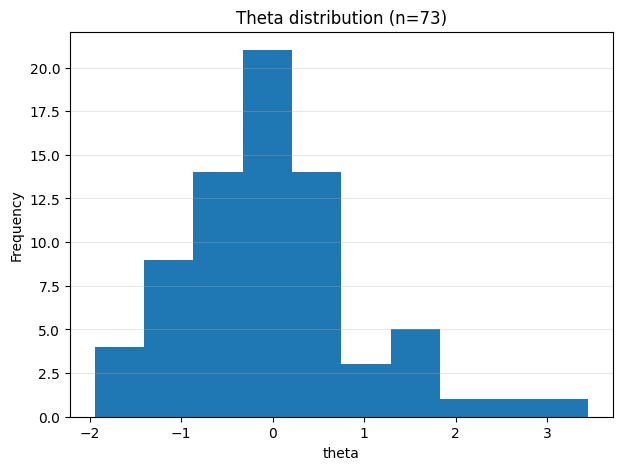

In [63]:
plot_theta_histogram_all(theta_df, bins=10)

シミュレーション

In [64]:
import numpy as np
import pandas as pd
from dataclasses import dataclass

D = 1.702


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -40.0, 40.0)))


@dataclass
class MixedSimulationData:
    p_full_df: pd.DataFrame
    s2_full_df: pd.DataFrame
    r_bin_df: pd.DataFrame
    p_mix_df: pd.DataFrame
    s2_mix_df: pd.DataFrame
    r_mix_df: pd.DataFrame
    mask_mix_df: pd.DataFrame

    # true parameters for simulation diagnostics
    a_true: np.ndarray
    b_true: np.ndarray
    theta_full_true: np.ndarray
    theta_bin_true: np.ndarray
    theta_mix_true: np.ndarray

    # optional underlying means
    mu_full: np.ndarray
    mu_bin: np.ndarray
    mu_mix: np.ndarray

    R_l: int
    R_b: int
    binary_fraction: float


def simulate_itemwise_mixed_dataframes(
    n_full_probability=100,
    n_full_binary=100,
    n_mixed=100,
    n_items=100,
    R_l=5,
    R_b=5,
    binary_fraction=0.3,
    seed=42,
    item_b_low=-2.0,
    item_b_high=2.0,
    a_low=0.5,
    a_high=2.0,
):
    """
    Generate simulation DataFrames for item-wise mixed hybrid IRT.

    Generated DataFrames:
      1. p_full_df   : mean correct probabilities for fully logprobs-measured LLMs
      2. s2_full_df  : variance of repeated correct probabilities for fully logprobs-measured LLMs
      3. r_bin_df    : correct counts for fully binary-measured LLMs
      4. p_mix_df    : mean correct probabilities for item-wise mixed LLMs
      5. s2_mix_df   : variance of repeated correct probabilities for item-wise mixed LLMs
      6. r_mix_df    : correct counts for item-wise mixed LLMs
      7. mask_mix_df : 1 = use probability/logprobs, 0 = use binary

    Notes:
      - p_mix_df, s2_mix_df, and r_mix_df are generated mechanically for all cells.
      - mask_mix_df decides which observation channel is actually used in fitting.
      - binary_fraction controls the fraction of 0s in mask_mix_df.
    """
    if not (0.0 <= binary_fraction <= 1.0):
        raise ValueError("binary_fraction must be between 0 and 1.")

    rng = np.random.default_rng(seed)

    # Item parameters
    a_true = rng.uniform(a_low, a_high, n_items)
    b_true = rng.uniform(item_b_low, item_b_high, n_items)

    # Ability parameters
    theta_full_true = rng.normal(0.0, 1.0, n_full_probability)
    theta_bin_true = rng.normal(0.0, 1.0, n_full_binary)
    theta_mix_true = rng.normal(0.0, 1.0, n_mixed)

    item_names = [f"item_{j+1:03d}" for j in range(n_items)]
    full_names = [f"prob_llm_{g+1:03d}" for g in range(n_full_probability)]
    bin_names = [f"bin_llm_{g+1:03d}" for g in range(n_full_binary)]
    mix_names = [f"mix_llm_{g+1:03d}" for g in range(n_mixed)]

    def generate_probability_observations(theta):
        """
        Generate repeated probability-scale observations.

        p_rep = mu + Normal(0, sigma_p^2)
        clipped to [0, 1].

        sigma_p is largest around mu=0.5 and smallest near 0/1:
        sigma_p = 0.01 + 0.2 * np.sqrt(mu * (1.0 - mu))
        """
        eta = D * a_true[None, :] * (theta[:, None] - b_true[None, :])
        mu = sigmoid(eta)

        sigma_p = 0.01 + 0.2 * np.sqrt(mu * (1.0 - mu))
        sigma_p = np.maximum(sigma_p, 0.0)

        p_rep = mu[:, :, None] + rng.normal(
            loc=0.0,
            scale=sigma_p[:, :, None],
            size=(len(theta), n_items, R_l),
        )

        p_rep = np.clip(p_rep, 0.0, 1.0)

        p_bar = p_rep.mean(axis=2)
        s2_p = p_rep.var(axis=2, ddof=1)

        return p_bar, s2_p, mu

    def generate_binary_counts(theta):
        """
        Generate Binomial correct counts.
        """
        eta = D * a_true[None, :] * (theta[:, None] - b_true[None, :])
        mu = sigmoid(eta)
        r = rng.binomial(R_b, mu)
        return r, mu

    # 1-2. full probability group
    p_full, s2_full, mu_full = generate_probability_observations(theta_full_true)

    # 3. full binary group
    r_bin, mu_bin = generate_binary_counts(theta_bin_true)

    # 4-6. item-wise mixed group
    p_mix, s2_mix, mu_mix = generate_probability_observations(theta_mix_true)
    r_mix, _ = generate_binary_counts(theta_mix_true)

    # 7. mask for mixed group
    # 1 = use logprobs/probability, 0 = use binary
    mask_mix = (rng.random(size=(n_mixed, n_items)) >= binary_fraction).astype(int)

    # Convert to DataFrames
    p_full_df = pd.DataFrame(p_full, index=full_names, columns=item_names)
    s2_full_df = pd.DataFrame(s2_full, index=full_names, columns=item_names)

    r_bin_df = pd.DataFrame(r_bin, index=bin_names, columns=item_names)

    p_mix_df = pd.DataFrame(p_mix, index=mix_names, columns=item_names)
    s2_mix_df = pd.DataFrame(s2_mix, index=mix_names, columns=item_names)
    r_mix_df = pd.DataFrame(r_mix, index=mix_names, columns=item_names)
    mask_mix_df = pd.DataFrame(mask_mix, index=mix_names, columns=item_names)

    return MixedSimulationData(
        p_full_df=p_full_df,
        s2_full_df=s2_full_df,
        r_bin_df=r_bin_df,
        p_mix_df=p_mix_df,
        s2_mix_df=s2_mix_df,
        r_mix_df=r_mix_df,
        mask_mix_df=mask_mix_df,
        a_true=a_true,
        b_true=b_true,
        theta_full_true=theta_full_true,
        theta_bin_true=theta_bin_true,
        theta_mix_true=theta_mix_true,
        mu_full=mu_full,
        mu_bin=mu_bin,
        mu_mix=mu_mix,
        R_l=R_l,
        R_b=R_b,
        binary_fraction=binary_fraction,
    )

In [82]:
sim = simulate_itemwise_mixed_dataframes(
    n_full_probability=4,
    n_full_binary=26,
    n_mixed=43,
    n_items=110,
    R_l=5,
    R_b=5,
    binary_fraction=0.33,
    seed=25,
)

p_full_df = sim.p_full_df
s2_full_df = sim.s2_full_df
r_bin_df = sim.r_bin_df

p_mix_df = sim.p_mix_df
s2_mix_df = sim.s2_mix_df
r_mix_df = sim.r_mix_df
mask_mix_df = sim.mask_mix_df

In [83]:
fit_sim = fit_hybrid_irt_with_itemwise_mixed(
    p_full=p_full_df,
    s2_full=s2_full_df,
    r_bin=r_bin_df,
    p_mix=p_mix_df,
    s2_mix=s2_mix_df,
    r_mix=r_mix_df,
    mask_mix=mask_mix_df,
    R_l=sim.R_l,
    R_b=sim.R_b,
    c_tau=0.25,
    outer_iter=1000,
    item_maxiter=1000,
    verbose=True,
)

[iter 001] obj=13370.344709 | rel_dL=1.208e-01 | max_dparam=1.967e+00 | converged=False
[iter 002] obj=13364.869022 | rel_dL=4.095e-04 | max_dparam=6.774e-02 | converged=False
[iter 003] obj=13364.560788 | rel_dL=2.306e-05 | max_dparam=2.330e-02 | converged=False
[iter 004] obj=13364.491635 | rel_dL=5.174e-06 | max_dparam=1.116e-02 | converged=False
[iter 005] obj=13364.475669 | rel_dL=1.195e-06 | max_dparam=5.652e-03 | converged=False
[iter 006] obj=13364.471708 | rel_dL=2.964e-07 | max_dparam=4.416e-03 | converged=False
[iter 007] obj=13364.470594 | rel_dL=8.334e-08 | max_dparam=1.547e-03 | converged=False
[iter 008] obj=13364.470179 | rel_dL=3.103e-08 | max_dparam=1.969e-03 | converged=False
[iter 009] obj=13364.470014 | rel_dL=1.233e-08 | max_dparam=8.434e-04 | converged=False
[iter 010] obj=13364.469949 | rel_dL=4.905e-09 | max_dparam=6.068e-04 | converged=False
[iter 011] obj=13364.469912 | rel_dL=2.766e-09 | max_dparam=4.307e-04 | converged=False
[iter 012] obj=13364.469891 | re

In [84]:
fit_sim

{'a': array([0.7612129 , 0.55331624, 0.78601501, 1.14319535, 0.61248437,
        0.8530057 , 2.61828148, 2.42494349, 0.64240791, 0.96283351,
        1.57630163, 2.14591097, 1.17767116, 1.57018201, 0.9999929 ,
        1.28235019, 1.91340801, 2.19267844, 1.07994959, 1.35851484,
        1.03031433, 1.10250094, 1.9598647 , 1.42850336, 1.96816227,
        1.51195755, 1.63869382, 0.76944568, 0.90182005, 1.44131066,
        0.87468433, 1.56952128, 1.85149265, 2.25442845, 0.47232603,
        0.80400786, 0.78026846, 1.35391046, 0.79665941, 1.93626976,
        0.725939  , 1.79688692, 2.02122038, 1.40557154, 1.12905312,
        2.20849536, 1.19754484, 0.98882949, 1.47449935, 0.7466109 ,
        0.79277431, 1.7504095 , 1.20957466, 0.94306304, 2.37464916,
        1.98834538, 0.6250226 , 1.3556775 , 1.11043512, 1.97665621,
        0.86421968, 1.01407855, 0.64386694, 2.09762337, 1.03934933,
        1.5653272 , 0.9533354 , 1.93611728, 1.77856916, 2.20314398,
        1.74002368, 0.87067149, 2.34176633,

In [71]:
def summarize_result(fit, sim):
    a_t,b_t,tf_t,tb_t,tm_t=align_true_mixed(sim)
    return {
        "binary_fraction_target": sim.binary_fraction,
        "binary_fraction_actual": float((sim.mask_mix_df.to_numpy()==0).mean()),
        "rmse_a": rmse(fit["a"], a_t),
        "rmse_b": rmse(fit["b"], b_t),
        "corr_a": corr(fit["a"], a_t),
        "corr_b": corr(fit["b"], b_t),
        "mean_a_se": float(np.sqrt(np.mean(fit["a_se"]**2))),
        "median_a_se": float(np.median(fit["a_se"])),
        "p90_a_se": float(np.quantile(fit["a_se"], .90)),
        "mean_b_se": float(np.sqrt(np.mean(fit["b_se"]**2))),
        "median_b_se": float(np.median(fit["b_se"])),
        "p90_b_se": float(np.quantile(fit["b_se"], .90)),
        "rmse_theta_full_probability": rmse(fit["theta_full_probability"], tf_t),
        "rmse_theta_binary": rmse(fit["theta_binary"], tb_t),
        "rmse_theta_mixed": rmse(fit["theta_mixed"], tm_t),
        "mean_theta_full_probability_se": float(np.sqrt(np.mean(fit["theta_full_probability_se"]**2))),
        "mean_theta_binary_se": float(np.sqrt(np.mean(fit["theta_binary_se"]**2))),
        "mean_theta_mixed_se": float(np.sqrt(np.mean(fit["theta_mixed_se"]**2))),
        "converged": fit["converged"],
        "n_iterations": fit["n_iterations"],
        "final_rel_obj_change": fit["final_relative_objective_change"],
        "final_max_param_change": fit["final_max_parameter_change"],
    }

def align_true_mixed(sim):
    return standardize_params_mixed(
        sim.a_true.copy(), sim.b_true.copy(),
        sim.theta_full_true.copy(), sim.theta_bin_true.copy(), sim.theta_mix_true.copy()
    )

In [85]:
rows=[]
rows.append(summarize_result(fit_sim, sim))
sim_df=pd.DataFrame(rows)
display_cols = ["binary_fraction_target","binary_fraction_actual","rmse_a","rmse_b","mean_a_se","mean_b_se",
                "rmse_theta_mixed","mean_theta_mixed_se","mean_theta_full_probability_se","mean_theta_binary_se","converged","n_iterations",
                "final_rel_obj_change","final_max_param_change"]
sim_df[display_cols]

,binary_fraction_target,binary_fraction_actual,rmse_a,rmse_b,mean_a_se,mean_b_se,rmse_theta_mixed,mean_theta_mixed_se,mean_theta_full_probability_se,mean_theta_binary_se,converged,n_iterations,final_rel_obj_change,final_max_param_change
0,0.33,0.338901,0.199939,0.082757,0.177681,0.09248,0.047896,0.050113,0.064224,0.076679,True,16,2.437200e-10,0.000076
